# FER-2013: разведочный анализ данных (EMO-6)

Цель – понять, с какими данными будет обучаться модель распознавания эмоций: объем и сплиты, баланс 7 классов,
качество изображений (пустые, низкоконтрастные, дубликаты), утечки между сплитами.

Источник: зеркало оригинального `fer2013.csv` на Hugging Face
(`Aaryan333/fer2013_train_publicTest_privateTest`, ревизия `da8d164`), три сплита Training / PublicTest / PrivateTest.
Загрузка – `fer-train prepare` (см. `ml/training/README.md`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from emotion_service.labels import LABELS

from fer_training.data import image_hashes, is_blank, load_fer2013

plt.rcParams["figure.dpi"] = 72
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sets = load_fer2013(ROOT / "data" / "fer2013")
pd.DataFrame(
    {name: {"изображений": len(s), "размер": "×".join(map(str, s.images.shape[1:]))} for name, s in sets.items()}
).T

,изображений,размер
train,28709,48×48
public_test,3589,48×48
private_test,3589,48×48


## 1. Распределение классов

In [2]:
counts = pd.DataFrame({name: s.class_counts() for name, s in sets.items()}, index=LABELS)
share = (counts / counts.sum() * 100).round(1)
table = counts.astype(str) + " (" + share.astype(str) + " %)"
table.loc["всего"] = counts.sum().astype(str)
display(table)
print("Дисбаланс train (max/min):", round(counts["train"].max() / counts["train"].min(), 1))

,train,public_test,private_test
angry,3995 (13.9 %),467 (13.0 %),491 (13.7 %)
disgust,436 (1.5 %),56 (1.6 %),55 (1.5 %)
fear,4097 (14.3 %),496 (13.8 %),528 (14.7 %)
happy,7215 (25.1 %),895 (24.9 %),879 (24.5 %)
sad,4830 (16.8 %),653 (18.2 %),594 (16.6 %)
surprise,3171 (11.0 %),415 (11.6 %),416 (11.6 %)
neutral,4965 (17.3 %),607 (16.9 %),626 (17.4 %)
всего,28709,3589,3589


Дисбаланс train (max/min): 16.5


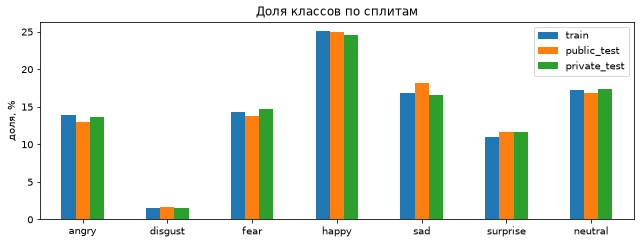

In [3]:
ax = share.plot.bar(figsize=(9, 3.5), rot=0)
ax.set_ylabel("доля, %")
ax.set_title("Доля классов по сплитам")
plt.tight_layout()

## 2. Примеры изображений

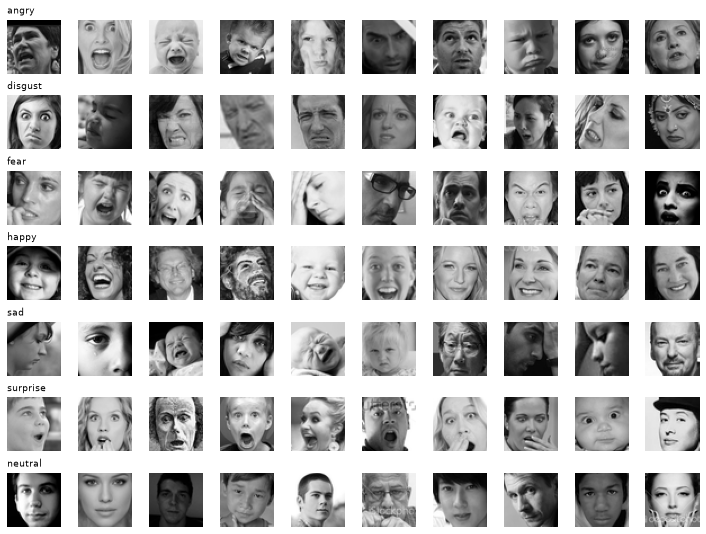

In [4]:
rng = np.random.default_rng(0)
train = sets["train"]
fig, axes = plt.subplots(len(LABELS), 10, figsize=(10, 7.5))
for row, label in enumerate(LABELS):
    idx = rng.choice(np.flatnonzero(train.labels == row), 10, replace=False)
    for col, i in enumerate(idx):
        axes[row, col].imshow(train.images[i], cmap="gray", vmin=0, vmax=255)
        axes[row, col].axis("off")
    axes[row, 0].set_title(label, loc="left", fontsize=9)
plt.tight_layout()

## 3. Качество изображений: яркость, контраст, пустые кадры

In [5]:
rows = []
for name, s in sets.items():
    flat = s.images.reshape(len(s), -1).astype(np.float32)
    rows.append(
        {
            "сплит": name,
            "яркость, среднее": flat.mean(1).mean().round(1),
            "контраст (σ), медиана": np.median(flat.std(1)).round(1),
            "однотонные (σ < 2)": int(is_blank(s.images).sum()),
            "низкий контраст (σ < 20)": int((flat.std(1) < 20).sum()),
            "темные (среднее < 40)": int((flat.mean(1) < 40).sum()),
            "пересвеченные (среднее > 215)": int((flat.mean(1) > 215).sum()),
        }
    )
pd.DataFrame(rows).set_index("сплит")

,"яркость, среднее","контраст (σ), медиана",однотонные (σ < 2),низкий контраст (σ < 20),темные (среднее < 40),пересвеченные (среднее > 215)
сплит,,,,,,
train,129.500000,53.599998,12,71,93,84
public_test,129.000000,53.599998,1,11,13,5
private_test,129.100006,53.900002,0,14,15,11


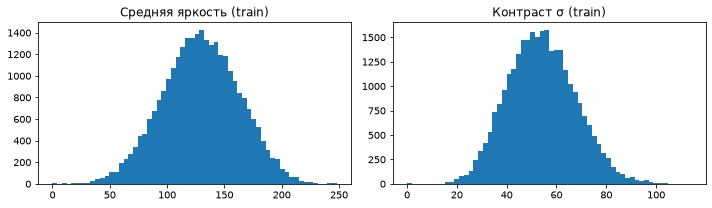

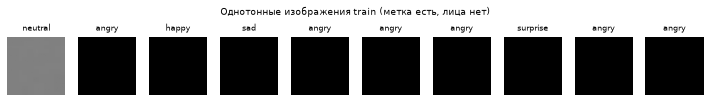

In [6]:
flat = train.images.reshape(len(train), -1).astype(np.float32)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(flat.mean(1), bins=60)
axes[0].set_title("Средняя яркость (train)")
axes[1].hist(flat.std(1), bins=60)
axes[1].set_title("Контраст σ (train)")
plt.tight_layout()

blank_idx = np.flatnonzero(is_blank(train.images))
fig, axes = plt.subplots(1, min(10, len(blank_idx)), figsize=(10, 1.4))
for ax, i in zip(np.atleast_1d(axes), blank_idx[:10], strict=False):
    ax.imshow(train.images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(LABELS[train.labels[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Однотонные изображения train (метка есть, лица нет)", fontsize=9)
plt.tight_layout()

## 4. Дубликаты и утечки между сплитами

In [7]:
hashes = {name: image_hashes(s.images) for name, s in sets.items()}
frame = pd.concat([pd.DataFrame({"hash": h, "split": name, "label": sets[name].labels}) for name, h in hashes.items()])
dup = frame[frame.duplicated("hash", keep=False)]
print("Изображений с точными копиями:", len(dup), "в", dup["hash"].nunique(), "группах")
conflict = dup.groupby("hash")["label"].nunique()
print("Группы копий с разными метками (шум разметки):", int((conflict > 1).sum()))
cross = dup.groupby("hash")["split"].nunique()
print("Группы, попавшие в несколько сплитов (утечка train ↔ test):", int((cross > 1).sum()))
leaked = dup[dup["hash"].isin(cross[cross > 1].index)]
pairs = leaked.groupby("hash")["split"].apply(lambda s: " + ".join(sorted(set(s))))
pairs.value_counts().rename("групп")

Изображений с точными копиями: 3369 в 1516 группах
Группы копий с разными метками (шум разметки): 57
Группы, попавшие в несколько сплитов (утечка train ↔ test): 557


split
private_test + train                  261
public_test + train                   253
private_test + public_test             26
private_test + public_test + train     17
Name: групп, dtype: int64

## 5. Средние лица классов

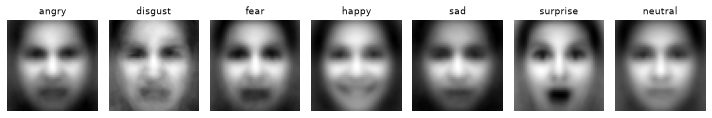

In [8]:
fig, axes = plt.subplots(1, len(LABELS), figsize=(10, 1.8))
for ax, (i, label) in zip(axes, enumerate(LABELS), strict=True):
    ax.imshow(train.images[train.labels == i].mean(0), cmap="gray")
    ax.set_title(label, fontsize=9)
    ax.axis("off")
plt.tight_layout()

## Выводы

1. **Объем и сплиты** совпадают с оригинальным `fer2013.csv`: 28 709 / 3 589 / 3 589, все изображения 48×48,
   оттенки серого. Тест целевой метрики – PublicTest + PrivateTest (7 178).
2. **Сильный дисбаланс**: happy – 25 %, disgust – 1,5 % (в 16,5 раза меньше). Пропорции в тесте те же, поэтому
   accuracy определяется в основном happy / neutral / sad, а disgust почти не влияет. Отсюда: кроме accuracy
   считать **macro-F1** и матрицу ошибок, проверить взвешенную функцию потерь и сэмплер.
3. **Качество изображений**: 12 однотонных кадров в train (и 1 в PublicTest) имеют метку, но лица на них нет –
   исключаются из обучения (`data.drop_blank`); тест не меняется. Около 0,3 % изображений с низким контрастом и
   около 0,6 % очень темных или пересвеченных – аугментации яркости, контраста и гаммы покрывают такие условия.
4. **Дубликаты и утечка**: 3 369 изображений имеют точные копии (1 516 групп); 57 групп копий размечены по-разному
   (шум разметки); **557 групп копий одновременно в train и test** – утечка, завышающая тестовую accuracy.
   Обучение очищается (`data.dedup`): удаляются копии тестовых изображений (692), группы с противоречивыми
   метками (73) и повторы внутри train (1 021) – остается 26 911 изображение (после исключения однотонных).
5. **Средние лица** классов заметно различаются только для happy и surprise (рот); fear, sad, angry и neutral
   похожи – ожидаемые взаимные ошибки модели.
6. **Низкое разрешение** (48×48): модель увеличивает кроп внутри графа до входа сети, кадр ВКС приводится к тому же
   виду общим препроцессингом (`emotion_service.preprocessing`), аугментации имитируют сжатие и понижение
   разрешения видео.